# 원하는 포즈로 이미지 만드는 도구 (FLUX.2-klein 4B + OpenPose)

참조 사진 속 사람의 **자세**를 뽑아, 그 자세를 한 **다른 인물·장면**을 만드는 Colab 튜토리얼입니다.

## 동작 흐름
```
참조 사진 ─▶ OpenPose(관절 추출) ─▶ 골격 이미지 ─┐
                                              ├─▶ FLUX.2-klein 4B ─▶ 같은 자세의 새 이미지
프롬프트 ("갑옷 입은 기사" 등) ───────────────┘
```

## 왜 ControlNet이 아니라 "참조 이미지" 방식인가
교안이 다룬 대로, 2026-07 기준 **FLUX.2용 Black Forest Labs 공식 ControlNet이 없습니다.** 대신 FLUX.2-klein은 참조 이미지를 넣고 말로 고치는 **편집(multi-reference editing)** 기능이 모델 안에 있습니다. 이 노트는 OpenPose 골격 이미지를 그 참조 이미지로 넣어 자세를 전달합니다.

- **방법 A (메인)**: 골격 이미지를 참조로 넣는다. 사진 속 인물의 얼굴·옷은 넘어가지 않고 자세만 전달된다.
- **방법 B (비교)**: 원본 사진을 참조로 넣고 "같은 자세로 인물을 바꿔라"라고 시킨다. 자세는 잘 유지되지만 원본의 배경·구도·체형도 따라올 수 있다.

## 실행 환경
- Colab **T4 GPU** (메뉴 `런타임 → 런타임 유형 변경 → T4 GPU`)
- 원본 FLUX.2-klein(BF16, 약 16GB)은 무료 Colab 시스템 RAM(약 13GB)을 넘으므로, 교안 Colab 데모와 같이 **GGUF Q4 양자화 모델(2.6GB)을 ComfyUI로 실행**합니다.
- 처음 한 번은 설치·다운로드로 5~10분 걸립니다. 위에서부터 차례로 실행하세요.

## 1. GPU 확인
이 셀은 GPU가 붙었는지와 VRAM 용량을 출력합니다. GPU가 없으면 여기서 멈춥니다.

In [15]:
# [셀 역할] GPU 확인. 무료 Colab은 보통 Tesla T4 (VRAM 약 15GB).
import torch
if not torch.cuda.is_available():
    raise SystemExit("GPU가 안 붙었습니다. 런타임 유형을 T4 GPU로 바꾸고 다시 실행하세요.")
p = torch.cuda.get_device_properties(0)
print(f"{p.name} / VRAM {p.total_memory / 1024**3:.1f}GB")

Tesla T4 / VRAM 14.6GB


## 2. 도구 설치
- **ComfyUI**: 이미지 생성 과정을 노드로 구성하는 도구. 화면 없이 **API 서버로만** 씁니다.
- **ComfyUI-GGUF**: 양자화 모델 파일(GGUF)을 읽는 확장.
- **controlnet_aux**: 사진에서 사람 관절을 뽑는 OpenPose 검출기가 들어 있는 라이브러리.

In [16]:
# [셀 역할] ComfyUI 본체 + GGUF 로더 + OpenPose 검출기 설치 (이미 있으면 건너뜀)
import os
%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone -q https://github.com/comfyanonymous/ComfyUI.git
%cd /content/ComfyUI
!pip install -q -r requirements.txt

%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone -q https://github.com/city96/ComfyUI-GGUF.git
%cd /content/ComfyUI
!pip install -q gguf controlnet_aux
print("완료: ComfyUI + GGUF 확장 + controlnet_aux 설치")

/content
/content/ComfyUI
/content/ComfyUI/custom_nodes
/content/ComfyUI
완료: ComfyUI + GGUF 확장 + controlnet_aux 설치


## 3. 모델 다운로드 (약 11GB)

| 역할 | 파일 | 크기 |
| --- | --- | --- |
| 디퓨전 모델 (그림을 그리는 본체) | `flux-2-klein-4b-Q4_K_M.gguf` | 2.6GB |
| 텍스트 인코더 (프롬프트를 숫자로, Qwen3-4B) | `qwen_3_4b.safetensors` | 약 8GB |
| VAE (이미지 ↔ 잠재 공간 변환) | `flux2-vae.safetensors` | 약 330MB |

출처는 교안 FLUX.2 Colab 데모와 같습니다. FLUX.2-klein 4B는 **Apache 2.0** 라이선스라 결과물을 공개 저장소에 올려도 됩니다.

In [17]:
# [셀 역할] 모델 파일 3종을 ComfyUI 표준 폴더에 내려받음 (이미 있으면 건너뜀)
import os
%cd /content/ComfyUI
for d in ["models/diffusion_models", "models/text_encoders", "models/vae"]:
    os.makedirs(d, exist_ok=True)

FILES = [
    ("https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
     "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf"),
    ("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
     "models/text_encoders/qwen_3_4b.safetensors"),
    ("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
     "models/vae/flux2-vae.safetensors"),
]
for url, path in FILES:
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"이미 있음: {path} ({os.path.getsize(path)/1e9:.2f} GB)")
        continue
    print(f"다운로드 중: {path}")
    !wget -q --show-progress -O "{path}" "{url}"
print("다운로드 완료")

/content/ComfyUI
이미 있음: models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf (2.60 GB)
이미 있음: models/text_encoders/qwen_3_4b.safetensors (8.04 GB)
이미 있음: models/vae/flux2-vae.safetensors (0.34 GB)
다운로드 완료


## 4. ComfyUI 서버 실행
ComfyUI를 백그라운드 API 서버(`http://127.0.0.1:8188`)로 띄우고, 준비될 때까지 기다립니다. 서버는 런타임이 살아 있는 동안 계속 돌아갑니다.

In [18]:
# [셀 역할] ComfyUI 서버를 백그라운드로 실행하고 준비될 때까지 대기
import subprocess, time, os
%cd /content/ComfyUI
!pkill -f "main.py" 2>/dev/null
time.sleep(2)
os.system("nohup python main.py --listen 0.0.0.0 --port 8188 > /content/comfyui.log 2>&1 &")

print("ComfyUI 기동 대기 중...")
for _ in range(90):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비")
        break
else:
    print("서버가 안 떴습니다. 로그 끝부분:")
    print(open("/content/comfyui.log").read()[-1500:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비


## 5. 그래프 한글 폰트
결과 비교 그림의 제목에 한글을 쓰기 위해 나눔고딕을 설치합니다.

In [19]:
# [셀 역할] matplotlib 한글 폰트 설정
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
print("한글 폰트 설정 완료")

한글 폰트 설정 완료


## 6. 참조 포즈 사진 올리기

**자세가 서로 다른 전신 사진 2~3장**을 올립니다. 이 셀을 실행하면 파일 선택 창이 뜹니다.

좋은 참조 사진의 조건:
- 사람이 **한 명**, **전신**이 다 보일 것 (발·손이 잘리면 관절을 못 찾음)
- 팔다리가 몸에 가려지지 않을 것
- 자세끼리 차이가 클 것 (예: 한 팔을 든 자세 / 앉은 자세 / 걷는 자세)

**저작권**: 결과물이 공개 GitHub에 올라가므로 **Unsplash, Pexels** 같은 무료 라이선스 사진을 쓰고, 사진 주소와 촬영자 이름을 아래 `PHOTO_CREDITS`에 적으세요. 이 내용이 `prompts.md`와 README에 그대로 들어갑니다.

파일은 올린 순서대로 `pose_01`, `pose_02`, ... 로 번호가 붙습니다.

In [20]:
# [셀 역할] 참조 사진 업로드 → /content/poses/ 에 pose_01.jpg, pose_02.jpg ... 로 저장
import os, shutil
from google.colab import files

POSE_DIR = "/content/poses"
os.makedirs(POSE_DIR, exist_ok=True)

uploaded = files.upload()                 # 파일 선택 창
POSE_FILES = []
for i, name in enumerate(uploaded.keys(), start=1):
    ext = os.path.splitext(name)[1].lower() or ".jpg"
    dst = f"{POSE_DIR}/pose_{i:02d}{ext}"
    shutil.move(name, dst)
    POSE_FILES.append(dst)
    print(f"{name} → {dst}")

# 사진 출처 (업로드 순서대로 채우기). 예: "Unsplash, 촬영자 홍길동, https://unsplash.com/photos/xxxx"
PHOTO_CREDITS = [
    "출처를 적으세요 (pose_01)",
    "출처를 적으세요 (pose_02)",
    "출처를 적으세요 (pose_03)",
]

Saving 스크린샷 2026-11-11 171953.png to 스크린샷 2026-11-11 171953.png
Saving 스크린샷 2026-11-11 172004.png to 스크린샷 2026-11-11 172004.png
Saving 스크린샷 2026-11-11 172007.png to 스크린샷 2026-11-11 172007.png
스크린샷 2026-11-11 171953.png → /content/poses/pose_01.png
스크린샷 2026-11-11 172004.png → /content/poses/pose_02.png
스크린샷 2026-11-11 172007.png → /content/poses/pose_03.png


## 7. 포즈 추출 (OpenPose)

사진에서 사람의 관절(머리, 어깨, 팔꿈치, 손목, 골반, 무릎, 발목 등 18개 점)을 찾아 **막대 인형 골격 이미지**로 그립니다. 이 골격 이미지가 방법 A의 참조 이미지가 됩니다.

사진은 생성에 쓰기 좋게 **약 100만 화소, 가로·세로 16의 배수**로 맞춥니다. 결과 이미지도 같은 크기로 만듭니다.

골격이 비어 있거나 관절이 이상하게 잡혔다면 그 사진은 바꾸는 편이 낫습니다.

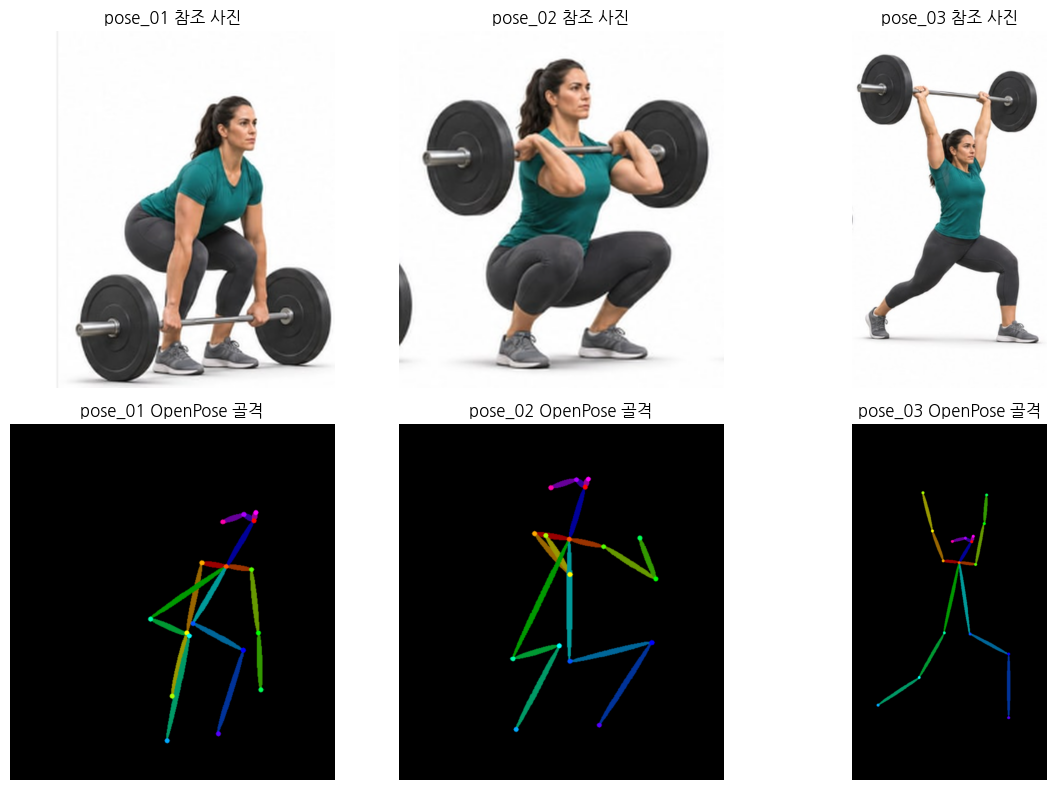

In [21]:
# [셀 역할] 참조 사진 크기 맞춤 + OpenPose 골격 추출 → 사진·골격 나란히 표시
from PIL import Image
from controlnet_aux import OpenposeDetector

openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")   # 첫 실행 시 가중치 다운로드

def fit_1mp(img, target=1024 * 1024):
    # 비율 유지, 약 1MP, 가로·세로 16의 배수
    w, h = img.size
    s = (target / (w * h)) ** 0.5
    nw, nh = max(16, round(w * s / 16) * 16), max(16, round(h * s / 16) * 16)
    return img.resize((nw, nh), Image.LANCZOS)

POSES = []   # (번호, 사진, 골격)
for path in POSE_FILES:
    num = os.path.basename(path).split(".")[0].split("_")[1]
    photo = fit_1mp(Image.open(path).convert("RGB"))
    skel = openpose(photo, detect_resolution=512, image_resolution=min(photo.size))
    skel = skel.resize(photo.size, Image.NEAREST)
    photo.save(f"{POSE_DIR}/pose_{num}_photo.png")
    skel.save(f"{POSE_DIR}/pose_{num}_skeleton.png")
    POSES.append((num, photo, skel))

fig, axes = plt.subplots(2, len(POSES), figsize=(4 * len(POSES), 8), squeeze=False)
for c, (num, photo, skel) in enumerate(POSES):
    axes[0, c].imshow(photo); axes[0, c].set_title(f"pose_{num} 참조 사진")
    axes[1, c].imshow(skel);  axes[1, c].set_title(f"pose_{num} OpenPose 골격")
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

## 8. 생성 함수 (참조 이미지 + 프롬프트 → ComfyUI)

ComfyUI에 보내는 워크플로(노드 연결)는 FLUX.2-klein 편집 방식을 따릅니다.

```
참조 이미지 ─ LoadImage ─ VAEEncode ─┐
프롬프트 ─ CLIPTextEncode ───────────┴─ ReferenceLatent ─▶ KSampler ─ VAEDecode ─ 저장
```

- `ReferenceLatent`: 참조 이미지를 잠재 공간으로 바꿔 프롬프트 조건에 붙이는 노드. 모델이 "이 그림을 보면서" 프롬프트를 그립니다.
- `STEPS = 4`, `CFG = 1.0`: FLUX.2-klein 4B(증류 모델)의 공식 권장값. CFG가 1이면 네거티브 프롬프트는 쓰이지 않습니다.
- `SEED` 고정: 조건 실험에서 결과 차이를 포즈·프롬프트 탓으로 말할 수 있게 합니다.

In [22]:
# [셀 역할] 참조 이미지 1장 + 프롬프트로 이미지를 생성하는 함수
import requests, json, time, urllib.parse, io, shutil

SERVER = "http://127.0.0.1:8188"
INPUT_DIR = "/content/ComfyUI/input"     # ComfyUI의 LoadImage가 읽는 폴더
SEED, STEPS, CFG = 1234, 4, 1.0

def generate_with_ref(ref_img, prompt, seed=SEED, steps=STEPS, cfg=CFG):
    os.makedirs(INPUT_DIR, exist_ok=True)
    ref_name = f"ref_{int(time.time() * 1000)}.png"
    ref_img.save(f"{INPUT_DIR}/{ref_name}")
    w, h = ref_img.size

    workflow = {
        "10": {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},
        "8":  {"class_type": "CLIPLoader",     "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},
        "4":  {"class_type": "VAELoader",      "inputs": {"vae_name": "flux2-vae.safetensors"}},
        "6":  {"class_type": "CLIPTextEncode", "inputs": {"text": prompt, "clip": ["8", 0]}},          # 프롬프트
        "20": {"class_type": "LoadImage",      "inputs": {"image": ref_name}},                         # 참조 이미지
        "21": {"class_type": "VAEEncode",      "inputs": {"pixels": ["20", 0], "vae": ["4", 0]}},      # 참조 → 잠재
        "22": {"class_type": "ReferenceLatent","inputs": {"conditioning": ["6", 0], "latent": ["21", 0]}},  # 조건에 참조 부착
        "7":  {"class_type": "ConditioningZeroOut", "inputs": {"conditioning": ["6", 0]}},             # 빈 네거티브
        "5":  {"class_type": "EmptyLatentImage", "inputs": {"width": w, "height": h, "batch_size": 1}},
        "3":  {"class_type": "KSampler", "inputs": {
                  "seed": int(seed), "steps": int(steps), "cfg": float(cfg),
                  "sampler_name": "euler", "scheduler": "simple", "denoise": 1.0,
                  "model": ["10", 0], "positive": ["22", 0], "negative": ["7", 0], "latent_image": ["5", 0]}},
        "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},
        "11": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "pose_tool"}},
    }
    r = requests.post(f"{SERVER}/prompt", json={"prompt": workflow, "client_id": "pose_tool"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:800]}")
    pid = r.json()["prompt_id"]

    for _ in range(600):                  # 최대 약 10분 (첫 장은 모델 로드로 느림)
        time.sleep(1)
        h_ = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        if pid not in h_:
            continue
        entry = h_[pid]
        if entry.get("status", {}).get("status_str") == "error":
            raise RuntimeError(json.dumps(entry["status"].get("messages", []), ensure_ascii=False)[:1200])
        img = entry["outputs"]["11"]["images"][0]
        q = urllib.parse.urlencode({"filename": img["filename"], "subfolder": img.get("subfolder", ""),
                                    "type": img.get("type", "output")})
        return Image.open(io.BytesIO(requests.get(f"{SERVER}/view?{q}", timeout=60).content)).convert("RGB")
    raise TimeoutError("생성 대기 시간 초과")

# 결과의 자세를 확인하는 함수: 결과에서 다시 OpenPose를 뽑아 참조 골격과 겹쳐 본다
def pose_overlay(ref_skel, out_img):
    out_skel = openpose(out_img, detect_resolution=512, image_resolution=min(out_img.size)).resize(ref_skel.size, Image.NEAREST)
    return out_skel, Image.blend(ref_skel, out_skel, 0.5)

print("생성 함수 준비 완료")

생성 함수 준비 완료


## 9. 프롬프트 정하기

교안의 **여섯 칸**(피사체·동작·카메라·조명·환경·스타일) 중 **동작은 비웁니다.** 자세는 참조 이미지가 정하기 때문입니다. 프롬프트에 "팔을 든다" 같은 동작을 적으면 참조 자세와 부딪힐 수 있습니다.

방법별로 앞뒤에 붙는 지시문이 다릅니다.
- **방법 A (골격 참조)**: "참조 이미지의 막대 인형과 같은 자세로 그려라. 막대 인형은 그리지 마라."
- **방법 B (사진 참조)**: "참조 사진의 사람을 다른 인물로 바꿔라. 자세는 똑같이 유지하라."

In [23]:
# [셀 역할] 실험에 쓸 인물·장면 설명과 방법별 프롬프트 조립 함수
SUBJECTS = {
    "A": "a firefighter in full protective gear and helmet, on a city street at dusk, "
         "soft warm streetlight, full body, photorealistic documentary photograph",
    "B": "a medieval knight in polished silver armor, in a stone castle courtyard, "
         "overcast daylight, full body, photorealistic photograph",
    "C": "an astronaut in a white spacesuit, on the grey surface of the moon with Earth in the black sky, "
         "full body, photorealistic photograph",
}

def prompt_skeleton(desc):   # 방법 A
    return (f"A photo of {desc}. The person's body pose exactly matches the stick-figure pose "
            f"in the reference image: same head, arm, and leg positions. "
            f"Do not draw the stick figure, lines, or dots; the background is a real scene.")

def prompt_photo(desc):      # 방법 B
    return (f"Replace the person in the reference photo with {desc}. "
            f"Keep exactly the same body pose, limb positions, and camera framing. "
            f"Change the clothing, face, and background to match the description.")

for k, v in SUBJECTS.items():
    print(k, ":", v)

A : a firefighter in full protective gear and helmet, on a city street at dusk, soft warm streetlight, full body, photorealistic documentary photograph
B : a medieval knight in polished silver armor, in a stone castle courtyard, overcast daylight, full body, photorealistic photograph
C : an astronaut in a white spacesuit, on the grey surface of the moon with Earth in the black sky, full body, photorealistic photograph


## 10. 기본 결과: 참조 사진과 같은 자세로 만들기 (방법 A)

포즈마다 인물 A(소방관)로 한 장씩 만듭니다. 이 결과가 `samples/output_XX.png`가 됩니다.

표의 네 번째 줄은 **자세 확인용 겹쳐 보기**입니다. 결과 이미지에서 다시 OpenPose를 뽑아 참조 골격과 50%씩 겹쳤습니다. 선이 한 줄로 겹치면 자세가 같고, 두 줄로 벌어진 곳이 어긋난 관절입니다.

완료: pose 01
완료: pose 02
완료: pose 03


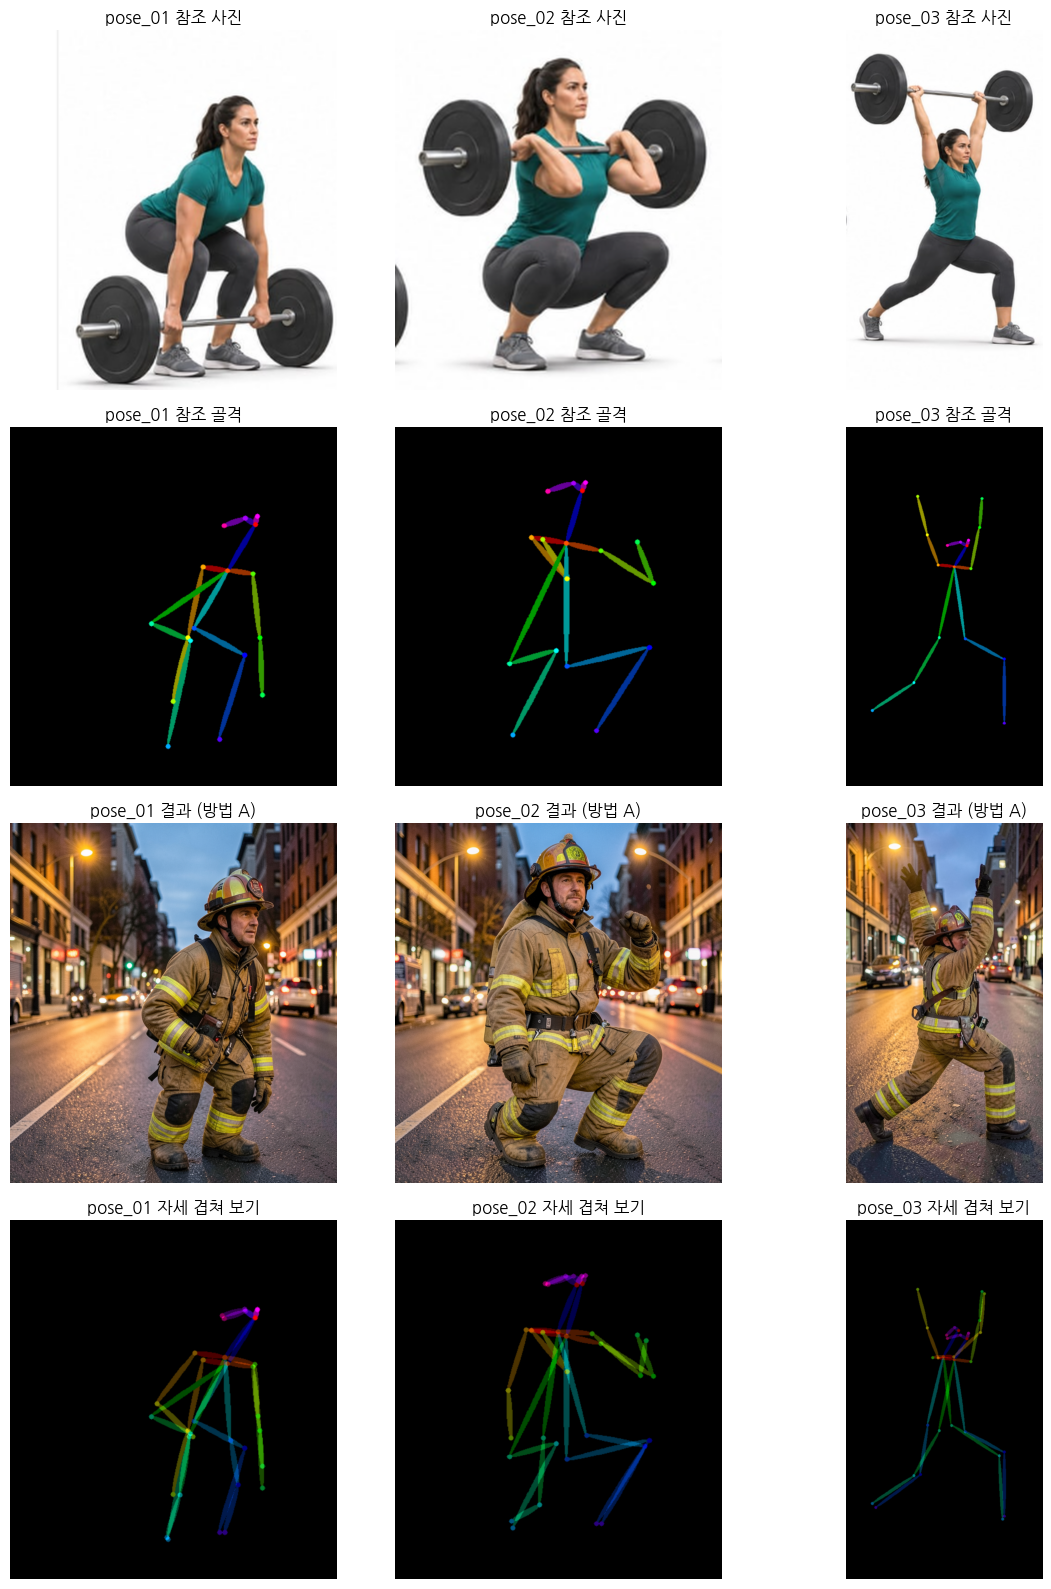

In [24]:
# [셀 역할] 포즈별로 방법 A(골격 참조) 생성 → 자세 겹쳐 보기까지 표시
OUT_DIR = "/content/samples"
os.makedirs(OUT_DIR, exist_ok=True)
LOG = []    # prompts.md 에 남길 기록

base = {}
for num, photo, skel in POSES:
    p = prompt_skeleton(SUBJECTS["A"])
    out = generate_with_ref(skel, p)
    out.save(f"{OUT_DIR}/output_{num}.png")
    photo.save(f"{OUT_DIR}/pose_{num}.png")
    skel.save(f"{OUT_DIR}/pose_{num}_skeleton.png")
    base[num] = out
    LOG.append(("기본 (방법 A)", f"pose_{num}", "A", p, f"output_{num}.png"))
    print("완료: pose", num)

fig, axes = plt.subplots(4, len(POSES), figsize=(4 * len(POSES), 16), squeeze=False)
for c, (num, photo, skel) in enumerate(POSES):
    _, overlay = pose_overlay(skel, base[num])
    for r, (img, title) in enumerate([(photo, "참조 사진"), (skel, "참조 골격"),
                                      (base[num], "결과 (방법 A)"), (overlay, "자세 겹쳐 보기")]):
        axes[r, c].imshow(img); axes[r, c].axis("off"); axes[r, c].set_title(f"pose_{num} {title}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/compare_base.png", dpi=90); plt.show()

## 11. 비교: 원본 사진을 참조로 넣으면 (방법 B)

같은 포즈·같은 인물 설명으로 원본 사진을 참조로 넣어 봅니다. 방법 A와 무엇이 다른지 봅니다.
- 자세가 더 정확한가?
- 원본 사진의 배경·구도·체형이 따라오는가?

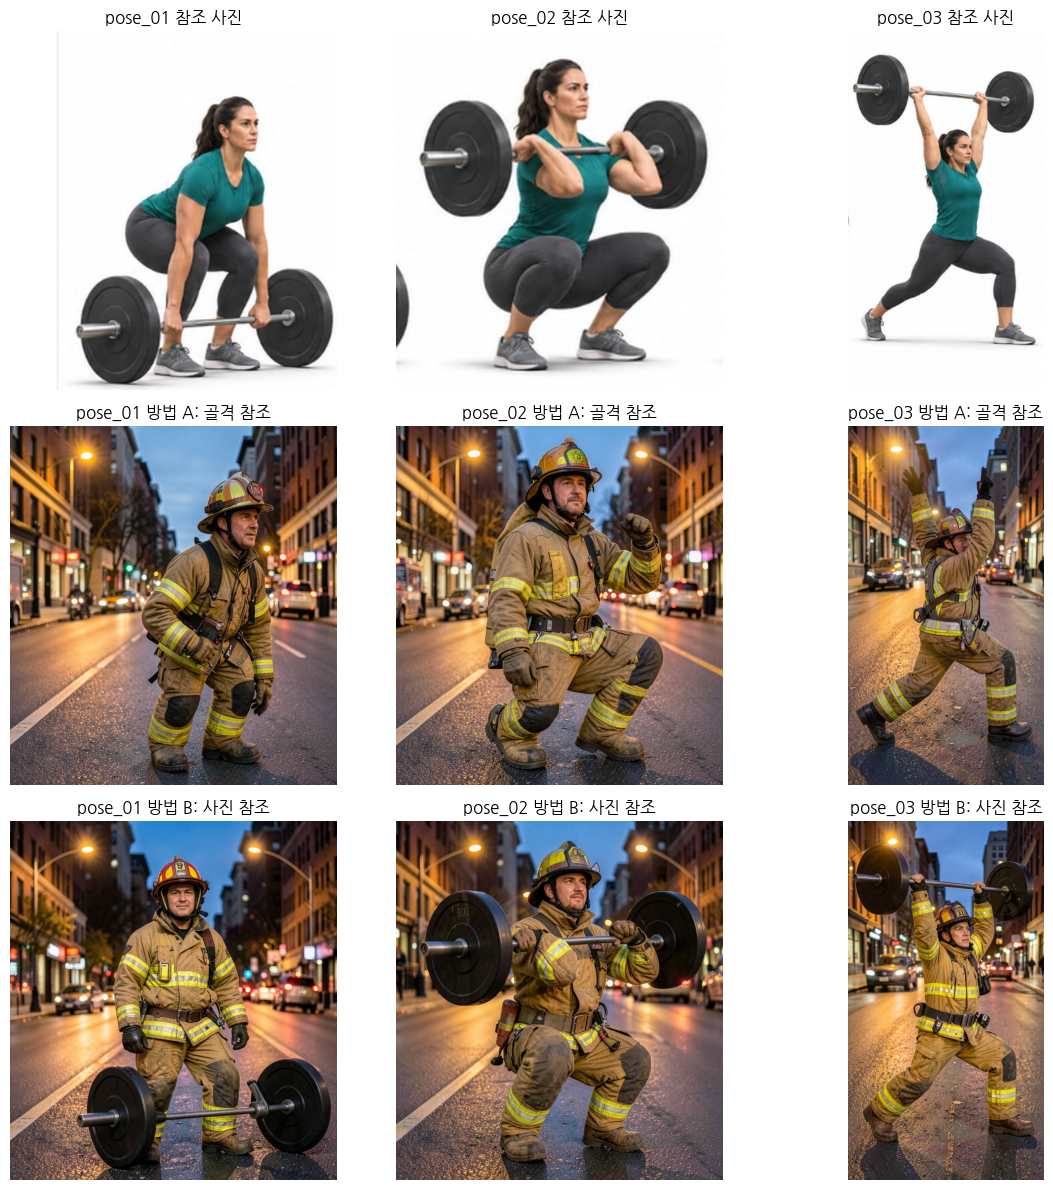

In [25]:
# [셀 역할] 포즈별로 방법 B(사진 참조) 생성 → 방법 A와 나란히 비교
alt = {}
for num, photo, skel in POSES:
    p = prompt_photo(SUBJECTS["A"])
    out = generate_with_ref(photo, p)
    out.save(f"{OUT_DIR}/output_{num}_photo_ref.png")
    alt[num] = out
    LOG.append(("비교 (방법 B)", f"pose_{num}", "A", p, f"output_{num}_photo_ref.png"))

fig, axes = plt.subplots(3, len(POSES), figsize=(4 * len(POSES), 12), squeeze=False)
for c, (num, photo, skel) in enumerate(POSES):
    for r, (img, title) in enumerate([(photo, "참조 사진"), (base[num], "방법 A: 골격 참조"),
                                      (alt[num], "방법 B: 사진 참조")]):
        axes[r, c].imshow(img); axes[r, c].axis("off"); axes[r, c].set_title(f"pose_{num} {title}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/compare_method.png", dpi=90); plt.show()

## 12. 조건 실험 1: 같은 포즈, 다른 프롬프트

포즈는 `pose_01`로 고정하고 인물 설명만 A(소방관) / B(기사) / C(우주비행사)로 바꿉니다. 방법 A를 씁니다.
**확인할 것**: 프롬프트가 바뀌어도 자세가 유지되는가? 갑옷·우주복처럼 몸을 가리는 옷에서 자세가 무너지지 않는가?

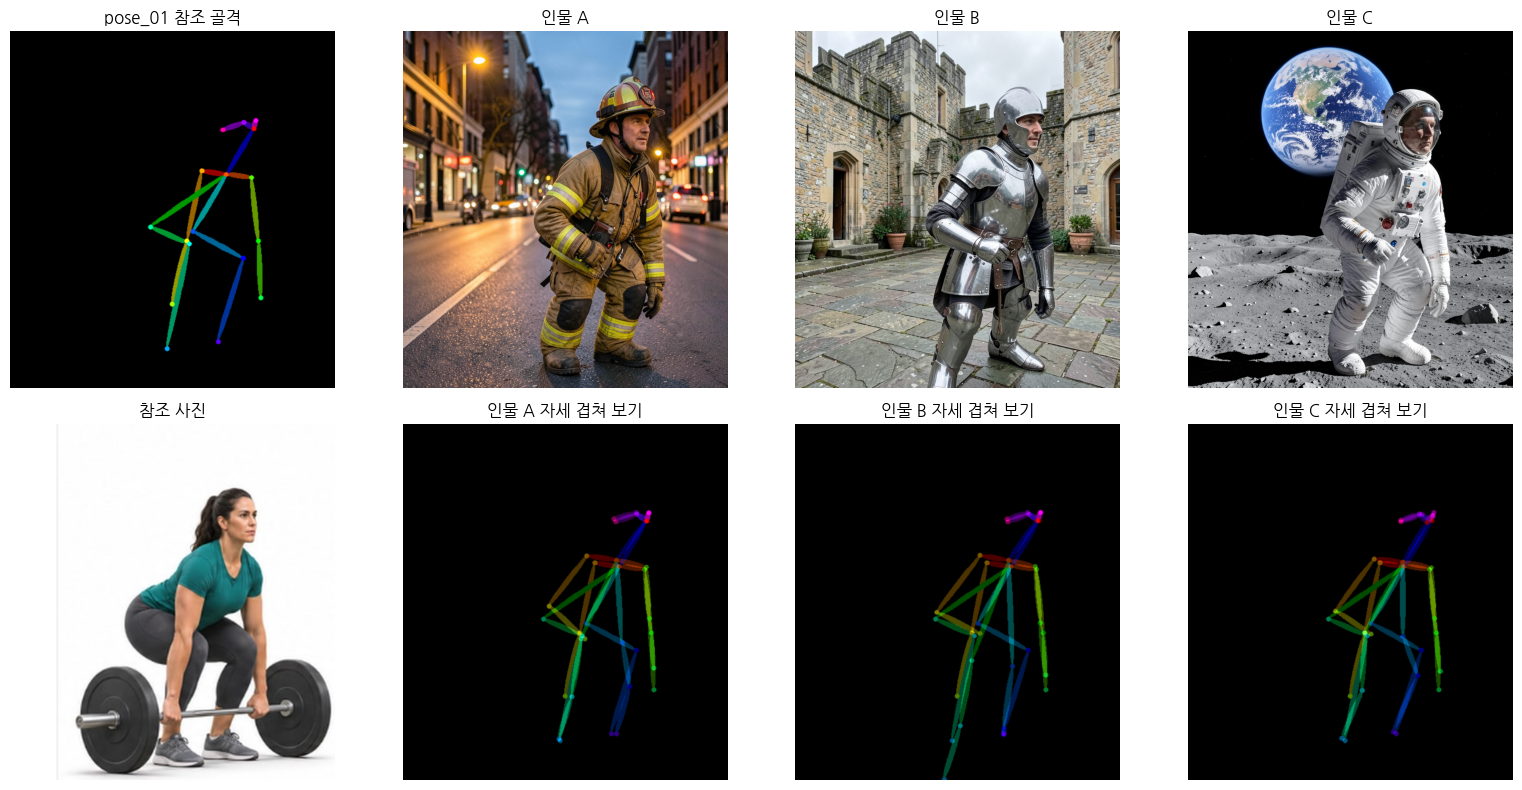

In [26]:
# [셀 역할] 같은 포즈(pose_01) × 인물 A/B/C
num0, photo0, skel0 = POSES[0]
exp1 = {}
for key in ["A", "B", "C"]:
    p = prompt_skeleton(SUBJECTS[key])
    out = base[num0] if key == "A" else generate_with_ref(skel0, p)
    out.save(f"{OUT_DIR}/exp1_pose{num0}_{key}.png")
    exp1[key] = out
    LOG.append(("실험 1: 같은 포즈", f"pose_{num0}", key, p, f"exp1_pose{num0}_{key}.png"))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes[0, 0].imshow(skel0); axes[0, 0].set_title(f"pose_{num0} 참조 골격")
axes[1, 0].imshow(photo0); axes[1, 0].set_title("참조 사진")
for c, key in enumerate(["A", "B", "C"], start=1):
    _, ov = pose_overlay(skel0, exp1[key])
    axes[0, c].imshow(exp1[key]); axes[0, c].set_title(f"인물 {key}")
    axes[1, c].imshow(ov);        axes[1, c].set_title(f"인물 {key} 자세 겹쳐 보기")
for a in axes.flat: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/exp1_same_pose.png", dpi=90); plt.show()

## 13. 조건 실험 2: 다른 포즈, 같은 프롬프트

인물 설명은 B(기사)로 고정하고 포즈만 바꿉니다.
**확인할 것**: 포즈를 바꾸면 결과 자세가 따라 바뀌는가? 어떤 자세(앉기, 팔 뻗기 등)에서 잘 안 따라오는가?

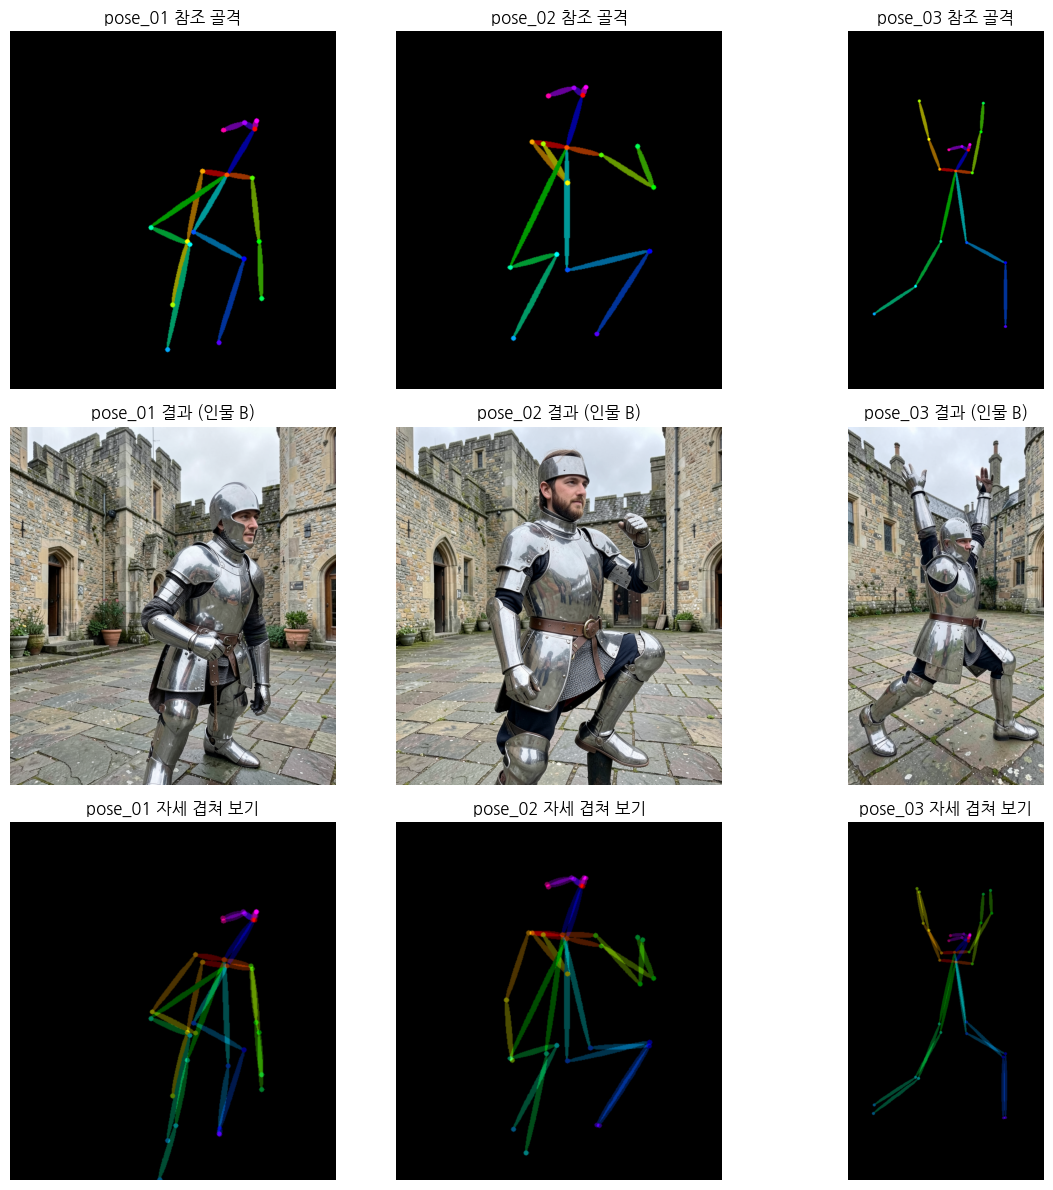

In [27]:
# [셀 역할] 다른 포즈 × 같은 인물(B)
exp2 = {}
for num, photo, skel in POSES:
    p = prompt_skeleton(SUBJECTS["B"])
    out = exp1["B"] if num == num0 else generate_with_ref(skel, p)
    out.save(f"{OUT_DIR}/exp2_pose{num}_B.png")
    exp2[num] = out
    LOG.append(("실험 2: 같은 프롬프트", f"pose_{num}", "B", p, f"exp2_pose{num}_B.png"))

fig, axes = plt.subplots(3, len(POSES), figsize=(4 * len(POSES), 12), squeeze=False)
for c, (num, photo, skel) in enumerate(POSES):
    _, ov = pose_overlay(skel, exp2[num])
    for r, (img, title) in enumerate([(skel, "참조 골격"), (exp2[num], "결과 (인물 B)"), (ov, "자세 겹쳐 보기")]):
        axes[r, c].imshow(img); axes[r, c].axis("off"); axes[r, c].set_title(f"pose_{num} {title}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/exp2_same_prompt.png", dpi=90); plt.show()

## 13-1. 조건 실험 3: 같은 골격에 자세를 말로 보충하면

pose_01(데드리프트 준비 자세)에서 결과 인물이 **키가 작고 다리가 짧게(난쟁이처럼)** 나왔다.
원인 추정: OpenPose 골격은 2D라 깊이 정보가 없다. 엉덩이를 뒤로 뺀 자세에서는 허벅지가 카메라 쪽을 향해 짧게 찍히는데(단축), 모델은 이것을 "짧게 보이는 정상 체형"이 아니라 "실제로 짧은 다리"로 해석했다.

골격은 그대로 두고 프롬프트만 세 단계로 바꿔 체형이 나아지는지 본다.
- **기본**: 기존 프롬프트 (동작 칸 비움)
- **+ 자세 설명**: 엉덩이를 접고 상체를 숙인 자세, 측면 3/4 시점, 정상 체형을 말로 보충
- **+ 자세 설명 + 문맥**: 바닥의 바벨을 잡으려는 상황까지 추가 (이 자세가 자연스러운 이유를 줌)

완료: 인물 A
완료: 인물 B


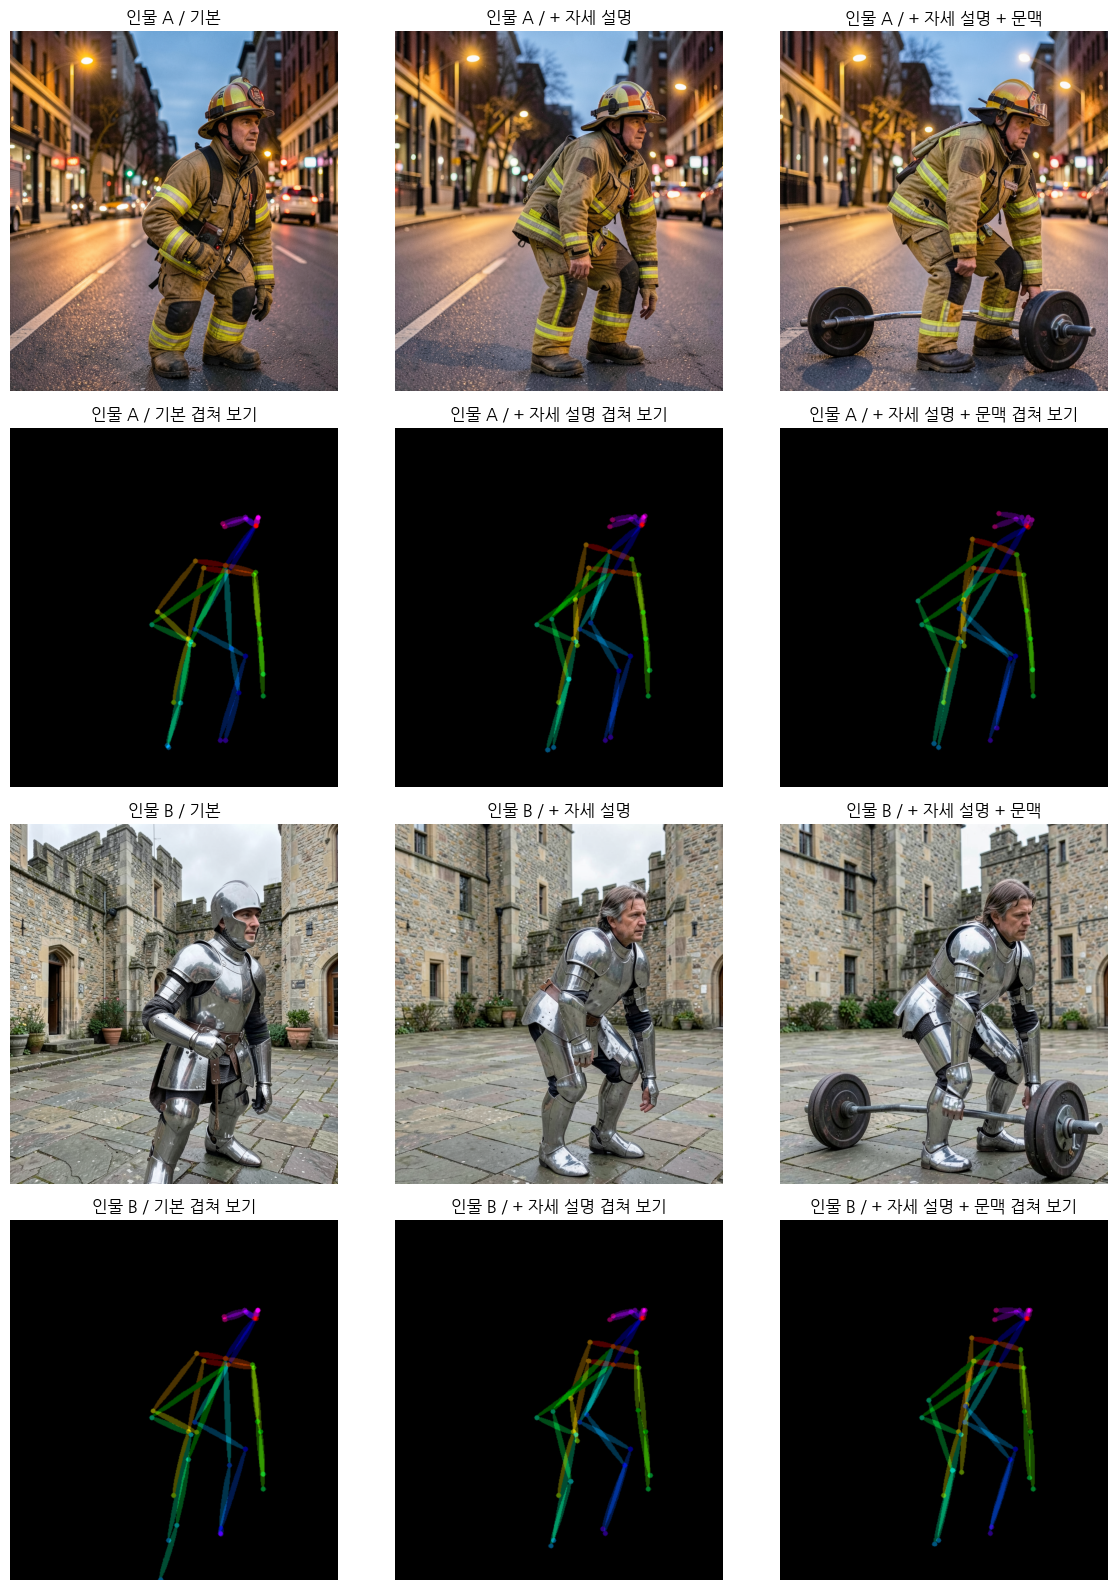

In [29]:
# [셀 역할] pose_01 골격 고정, 프롬프트에 자세 설명·문맥을 보충해 체형 변화 비교 (인물 A, B)
POSE_TEXT = ("bending forward at the hips with a flat back, hips pushed back, knees slightly bent, "
             "arms hanging straight down, seen from a three-quarter side view, "
             "normal adult body proportions with long legs")
CONTEXT = "reaching down to grip a loaded barbell resting on the floor in front of the shins"

def prompt_skeleton_plus(desc, extra):
    # 방법 A 프롬프트에 자세 설명을 끼워 넣는다
    return (f"A photo of {desc}. The person is {extra}. "
            f"The person's body pose exactly matches the stick-figure pose in the reference image: "
            f"same head, arm, and leg positions. "
            f"Do not draw the stick figure, lines, or dots; the background is a real scene.")

num0, photo0, skel0 = POSES[0]          # pose_01 (데드리프트 준비 자세)
VARIANTS = [
    ("기본",               None),
    ("+ 자세 설명",        POSE_TEXT),
    ("+ 자세 설명 + 문맥", f"{POSE_TEXT}, {CONTEXT}"),
]
reuse = {"A": base[num0], "B": exp1["B"]}   # '기본'은 앞에서 만든 결과를 그대로 쓴다

exp3 = {}
for key in ["A", "B"]:
    for vi, (vname, extra) in enumerate(VARIANTS):
        if extra is None:
            p, out = prompt_skeleton(SUBJECTS[key]), reuse[key]
        else:
            p = prompt_skeleton_plus(SUBJECTS[key], extra)
            out = generate_with_ref(skel0, p)
        fname = f"exp3_pose{num0}_{key}_v{vi}.png"
        out.save(f"{OUT_DIR}/{fname}")
        exp3[(key, vi)] = out
        LOG.append((f"실험 3: 자세 보충 ({vname})", f"pose_{num0}", key, p, fname))
    print("완료: 인물", key)

# 인물마다 2줄(결과 / 자세 겹쳐 보기) × 3열(프롬프트 단계)
fig, axes = plt.subplots(4, 3, figsize=(12, 16))
for r, key in enumerate(["A", "B"]):
    for c, (vname, _) in enumerate(VARIANTS):
        out = exp3[(key, c)]
        _, ov = pose_overlay(skel0, out)
        axes[2 * r, c].imshow(out);    axes[2 * r, c].set_title(f"인물 {key} / {vname}")
        axes[2 * r + 1, c].imshow(ov); axes[2 * r + 1, c].set_title(f"인물 {key} / {vname} 겹쳐 보기")
for a in axes.flat: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/exp3_pose_text.png", dpi=90); plt.show()

## 14. 결과 저장: samples/ + prompts.md 내려받기

GitHub에 올릴 `samples/` 폴더와 `prompts.md`를 만들어 zip으로 내려받습니다.
Colab은 큰 출력 이미지를 노트에 저장하지 않을 때가 있으니, 공유용 이미지는 이 zip으로 챙기세요.

zip 안의 구성:
- `samples/pose_XX.png` 참조 사진, `pose_XX_skeleton.png` 골격, `output_XX.png` 결과(방법 A)
- `samples/output_XX_photo_ref.png` 방법 B 결과, `exp1_*`, `exp2_*` 조건 실험 결과, `compare_*.png` 비교 그림
- `prompts.md` 실험에 쓴 프롬프트·시드·설정·사진 출처

In [30]:
# [셀 역할] prompts.md 작성 + samples/ 와 함께 zip으로 내려받기
lines = ["# 테스트에 쓴 프롬프트", "",
         f"- 모델: FLUX.2-klein 4B (GGUF Q4_K_M), ComfyUI",
         f"- 설정: seed {SEED}, steps {STEPS}, CFG {CFG}, sampler euler / simple", "",
         "## 인물 설명", ""]
lines += [f"- **{k}**: {v}" for k, v in SUBJECTS.items()]
lines += ["", "## 실행 기록", "", "| 구분 | 포즈 | 인물 | 결과 파일 | 프롬프트 |", "| --- | --- | --- | --- | --- |"]
lines += [f"| {g} | {pose} | {k} | {f} | {p} |" for g, pose, k, p, f in LOG]
lines += ["", "## 참조 사진 출처", ""]
lines += [f"- pose_{n}: {PHOTO_CREDITS[i] if i < len(PHOTO_CREDITS) else '출처를 적으세요'}"
          for i, (n, _, _) in enumerate(POSES)]
open("/content/prompts.md", "w", encoding="utf-8").write("\n".join(lines))

%cd /content
!rm -f pose_tool_results.zip && zip -qr pose_tool_results.zip samples prompts.md
from google.colab import files
files.download("/content/pose_tool_results.zip")
print("\n".join(lines[:12]))

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 테스트에 쓴 프롬프트

- 모델: FLUX.2-klein 4B (GGUF Q4_K_M), ComfyUI
- 설정: seed 1234, steps 4, CFG 1.0, sampler euler / simple

## 인물 설명

- **A**: a firefighter in full protective gear and helmet, on a city street at dusk, soft warm streetlight, full body, photorealistic documentary photograph
- **B**: a medieval knight in polished silver armor, in a stone castle courtyard, overcast daylight, full body, photorealistic photograph
- **C**: an astronaut in a white spacesuit, on the grey surface of the moon with Earth in the black sky, full body, photorealistic photograph

## 실행 기록


## 15. 관찰 기록: 무엇을 바꿔 보았고, 어떻게 달라졌는가

설정: FLUX.2-klein 4B (GGUF Q4), seed 1234, 4 steps, CFG 1.0

### 도구 동작 (방법 A, 골격 참조, 인물 A 소방관)
| 포즈 | 참조 자세 | 결과 자세가 맞았나 | 어긋난 부분 |
| --- | --- | --- | --- |
| pose_01 | 바벨을 들기 직전 (엉덩이 뒤로, 무릎 굽힘) | 맞음 | 한쪽 팔 위치가 조금 다름 |
| pose_02 | 프런트 스쿼트 (팔꿈치 앞, 깊게 앉음) | 다리는 맞음 | 팔. OpenPose가 한 팔을 무릎 쪽으로 잘못 검출했고, 결과는 잘못된 골격을 따름 |
| pose_03 | 양팔을 머리 위로 올린 런지 | 맞음 | 팔 벌어진 각도가 조금 넓음 |

- 결과에 막대 인형이 그려지지 않았고, 배경도 프롬프트대로 실제 장면이 나왔다.

### 방법 A(골격 참조) vs 방법 B(사진 참조)
- 방법 B는 바벨까지 결과에 따라왔다. 자세뿐 아니라 소품도 옮겨진다.
- 방법 B의 pose_01은 똑바로 선 자세로 바뀌어 자세 유지에 실패했다. pose_02·03은 잘 유지했다.
- 원본의 흰 배경은 따라오지 않았다. 배경은 프롬프트대로 바뀌었다.
- 정리: 자세만 옮기려면 A, 소품을 든 동작까지 옮기려면 B.

### 실험 1: 같은 포즈(pose_01), 다른 프롬프트 (A 소방관 / B 기사 / C 우주비행사)
- 세 인물 모두 같은 자세. 겹쳐 보기에서 거의 일치했다. 갑옷·우주복에서도 자세가 유지됐다.
- 고개 방향(오른쪽을 봄)까지 유지됐다.
- 참조는 여성인데 결과는 셋 다 남성. 골격에 성별 정보가 없고 프롬프트에도 안 적어서, 직업에 흔한 모습으로 채워진 것으로 보인다(교안의 "안 적은 칸은 모델이 정한다").
- 기사는 발이 화면 아래로 잘렸다.

### 실험 2: 다른 포즈, 같은 프롬프트 (B 기사)
- pose_01·03은 자세를 잘 따랐다.
- pose_02(깊은 스쿼트)는 한쪽 무릎을 들어 올린 자세로 바뀌었다. 같은 골격에서 소방관은 낮게 앉았으므로, 인물 설명에 따라 자세 해석이 달라진다(갑옷 입고 쪼그려 앉은 사진이 드물기 때문으로 추정).

### 실험 3: 같은 골격(pose_01)에 자세를 말로 보충
- 문제: 데드리프트 준비 자세에서 결과 인물이 키가 작고 다리가 짧게 나옴.
- 원인 추정: 엉덩이를 뒤로 뺀 자세가 2D로 찍히면서, 골격이 "상체를 세운 키 작은 사람" 모양이 됨. OpenPose 골격에는 깊이 정보가 없음.
- 프롬프트에 "엉덩이를 접고 숙인 자세, 정상 체형"을 보충 → 상체는 숙여졌지만 손을 무릎에 짚은 어색한 자세가 되고 다리는 여전히 짧음. 겹쳐 보기에서 골격 일치도는 오히려 떨어짐.
- 골격(세운 상체)과 프롬프트(숙인 상체)가 충돌해 중간 자세로 절충된 것으로 보임. 프롬프트가 길어지면서 기사의 투구가 사라지는 부작용도 생김.
- 바벨 문맥을 추가하면 자세는 가장 자연스러웠지만 원하지 않은 소품(바벨)이 생김.
- 결론: 깊이가 애매한 자세는 프롬프트로 보충해도 해결되지 않음. 측면에서 찍은 참조 사진이 낫다.

### 한계
- OpenPose 검출이 정확도의 상한. 골격이 틀리면 결과도 틀린다.
- 다리가 겹치는 깊은 앉은 자세에 약하다.
- 손 관절을 쓰지 않아 손 모양은 제어되지 않는다.
- 결과 비율은 참조 사진 비율을 따르고, 발이 잘리는 경우가 있다.
- 팔다리가 카메라 쪽을 향하는 자세는 2D 골격에서 짧게 잡혀 체형이 압축된다.